# 03 — Binary Logistic Regression with XinML

Classify examples in the bundled
[Breast Cancer Wisconsin Diagnostic dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html)
using the custom NumPy Logistic Regression model.

The 30 input features summarize measurements of cell nuclei from
digitized images. Labels are 0 = malignant and 1 = benign.
This notebook demonstrates binary classification, training-only
standardization, gradient descent, and held-out evaluation.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from xinml import LogisticRegression

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
assert LogisticRegression.__module__ == "xinml.logistic_regression"

## 1. Load the data and use a stratified split

Reserve 20% for testing with random_state=42. Stratification preserves
approximately the same class proportions in each subset. We will use
training rows for exploratory plots, scaling, and optimization.

In [2]:
dataset = load_breast_cancer(as_frame=True)
X, y = dataset.data, dataset.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
assert set(X_train.index).isdisjoint(X_test.index)
display(pd.Series({
    "Total observations": len(X),
    "Features": X.shape[1],
    "Training observations": len(X_train),
    "Test observations": len(X_test),
}, name="Dataset and split").to_frame())
class_counts = pd.DataFrame({
    "All": y.value_counts().sort_index(),
    "Train": y_train.value_counts().sort_index(),
    "Test": y_test.value_counts().sort_index(),
})
class_counts.index = ["Malignant (0)", "Benign (1)"]
display(class_counts)

,Dataset and split
Total observations,569
Features,30
Training observations,455
Test observations,114


,All,Train,Test
Malignant (0),212,170,42
Benign (1),357,285,72


## 2. Explore the training data

Inspect missing values, a few representative features, and class
counts. The radius histogram compares training examples from the two
classes; there may still be overlap between their feature values.

Missing training values: 0


,mean radius,mean texture,mean area
count,455.00,455.00,455.00
mean,14.07,19.25,648.54
std,3.50,4.41,344.94
min,6.98,9.71,143.50
25%,11.64,16.00,415.65
50%,13.27,18.82,541.80
75%,15.74,21.71,770.05
max,28.11,39.28,2499.00


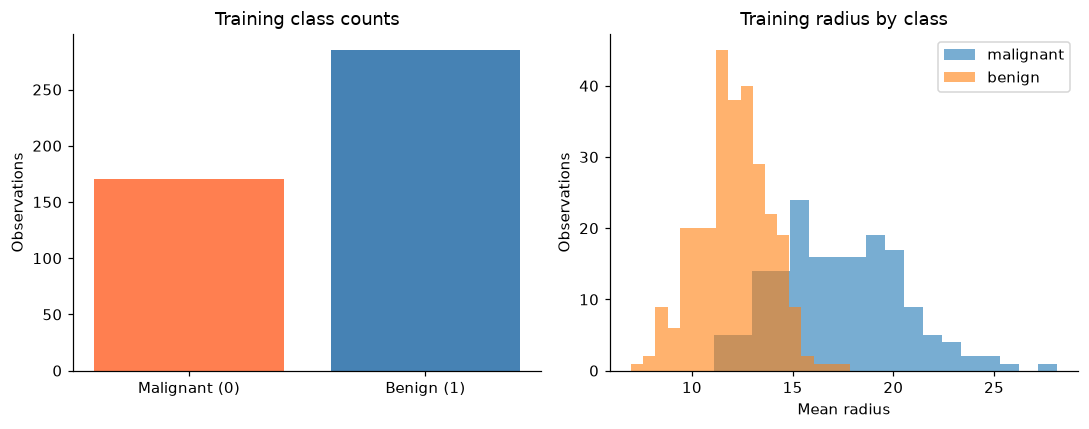

In [3]:
assert X_train.isna().sum().sum() == 0
assert y_train.isna().sum() == 0
print("Missing training values:", int(X_train.isna().sum().sum()))
display(X_train[["mean radius", "mean texture", "mean area"]]
        .describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(["Malignant (0)", "Benign (1)"],
            y_train.value_counts().sort_index(), color=["coral", "steelblue"])
axes[0].set(title="Training class counts", ylabel="Observations")
for label, name in enumerate(dataset.target_names):
    axes[1].hist(X_train.loc[y_train == label, "mean radius"], bins=18,
                 alpha=0.6, label=name)
axes[1].set(title="Training radius by class",
            xlabel="Mean radius", ylabel="Observations")
axes[1].legend()
fig.tight_layout()
plt.show()

## 3. Standardize without leaking test information

Features such as area and smoothness have very different magnitudes.
Standardization helps one gradient descent learning rate work across
columns. Learn means and standard deviations from X_train only.
The test set is transformed with those same training statistics.

In [4]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
assert scaler.n_samples_seen_ == len(X_train)
np.testing.assert_allclose(scaler.mean_, X_train.mean().to_numpy())
np.testing.assert_allclose(X_train_scaled.mean(axis=0), 0.0, atol=1e-12)

## 4. Train the XinML classifier

The model starts from zero weights and performs 2,000 batch gradient
updates with learning_rate=0.1. Each update uses all training samples to minimize binary
cross-entropy. These settings are fixed
in advance; we do not tune them against the test set.

In [5]:
model = LogisticRegression(learning_rate=0.1, max_iter=2000,
                           fit_intercept=True)
model.fit(X_train_scaled, y_train)
predictions = model.predict(X_test_scaled)
probabilities = model.predict_proba(X_test_scaled)
assert probabilities.shape == (len(y_test), 2)
assert np.all(np.isfinite(probabilities))
assert np.all((probabilities >= 0.0) & (probabilities <= 1.0))
np.testing.assert_allclose(probabilities.sum(axis=1), 1.0, atol=1e-12)
display(pd.DataFrame({
    "Actual class": y_test.to_numpy(),
    "Predicted class": predictions,
    "P(malignant = 0)": probabilities[:, 0],
    "P(benign = 1)": probabilities[:, 1],
}).head().round(3))

,Actual class,Predicted class,P(malignant = 0),P(benign = 1)
0,0,0,1.000,0.000
1,1,1,0.000,1.000
2,0,0,0.996,0.004
3,1,0,0.549,0.451
4,0,0,1.000,0.000


## 5. Evaluate accuracy and the confusion matrix

Accuracy is the fraction of correct test predictions. The confusion
matrix shows which kinds of mistakes were made, with true labels on
rows and predicted labels on columns. A malignant example predicted
benign appears in the upper-right cell. Accuracy alone hides this
distinction.

Test accuracy: 0.9649 (96.49%)


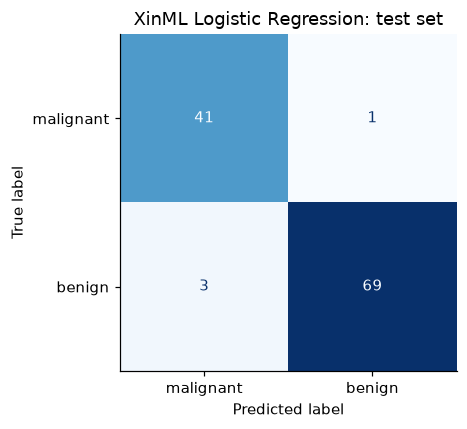

In [6]:
accuracy = model.score(X_test_scaled, y_test)
np.testing.assert_allclose(accuracy, accuracy_score(y_test, predictions))
matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
assert 0.0 <= accuracy <= 1.0
assert matrix.sum() == len(y_test)
np.testing.assert_allclose(np.trace(matrix) / matrix.sum(), accuracy)
print(f"Test accuracy: {accuracy:.4f} ({accuracy:.2%})")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(matrix, display_labels=dataset.target_names).plot(
    ax=ax, cmap="Blues", colorbar=False
)
ax.set_title("XinML Logistic Regression: test set")
fig.tight_layout()
plt.show()

## 6. Inspect optimization with the training loss

loss_history_ contains the loss at initialization and after each
gradient update. A decreasing training loss shows optimization
progress; it does not by itself prove that test performance improves.
The algorithm runs for a fixed iteration count without early stopping.

Training loss: 0.693147 -> 0.050878


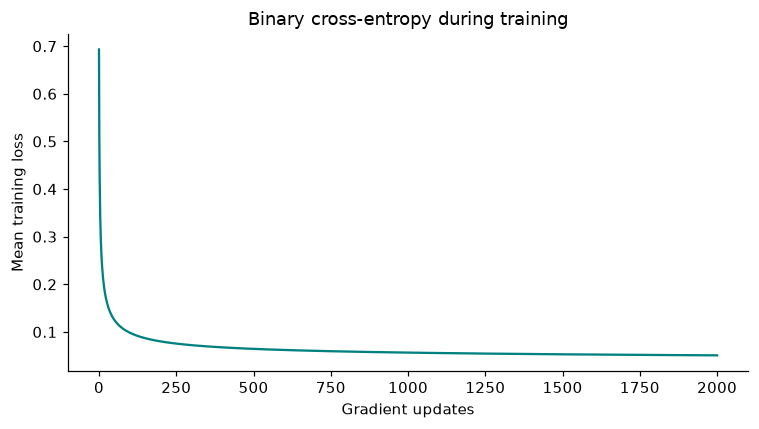

In [7]:
losses = np.asarray(model.loss_history_)
assert len(losses) == model.max_iter + 1
assert np.all(np.isfinite(losses))
assert losses[-1] < losses[0]
print(f"Training loss: {losses[0]:.6f} -> {losses[-1]:.6f}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(len(losses)), losses, color="teal")
ax.set(title="Binary cross-entropy during training",
       xlabel="Gradient updates", ylabel="Mean training loss")
fig.tight_layout()
plt.show()

## Conclusion and limitations

The test accuracy is **96.49%** (110 of 114 predictions correct). One malignant example was predicted benign, and three benign examples were predicted malignant. Training cross-entropy falls from **0.693147** to **0.050878** over 2,000 updates.

Class 1 probabilities refer to benign examples. This dataset and one fixed split do not establish performance on new populations. The model uses a linear decision boundary, no regularization, and a fixed 0.5 threshold; accuracy does not establish probability calibration.